# 07 — Switching-dynamics study (datasets dyn, dyn_fast)

The state-transition task from the first project design (generator ported unchanged from
`D:\HarunoKen\Twilight_MoE_Dynamics`): a 4-D state is rotated by one of three hidden matrices,
the matrix switches as a Markov chain, and the model predicts the next state from the states so far.

* structures: Dense, Dense-wide, **MoE, MoH, MoA, MoMHA** (MoM and MiTA excluded); no balancing
* attention is **causal** here (`state.causal`), input/output are linear maps R^4 <-> R^128
* data: `data_gen/dynamics.py` -> `E:\data\MoE_Structures_v2\dyn`, `dyn_fast`
* loop: `backbone/train.py train_dynamics_run`; metrics: `backbone/metrics_dyn.py`;
  references: `analysis/dyn_reference.py`; tables/figures: `analysis/dynamics.py`
* run the sweeps:  `python -m experiments.sweep --phase dyn_main`  and  `--phase dyn_variants`

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


## 1. What the data looks like

{
 "dataset": "dyn",
 "task": "dynamics",
 "generator": "Twilight_MoE_Dynamics dynamics.py (ported unchanged)",
 "length": 64,
 "burn_in": 128,
 "noise_std": 0.08,
 "stay_probability": 0.95,
 "angles": [
  [
   0.2,
   0.45
  ],
  [
   1.1,
   -0.65
  ],
  [
   -0.8,
   1.35
  ]
 ],
 "contraction": 0.94,
 "mean": [
  -7.632067718077451e-05,
  0.00010024543007602915,
  -6.072539326851256e-05,
  -1.6580732335569337e-05
 ],
 "std": [
  0.2339857518672943,
  0.23404726386070251,
  0.2343384325504303,
  0.23438963294029236
 ]
}


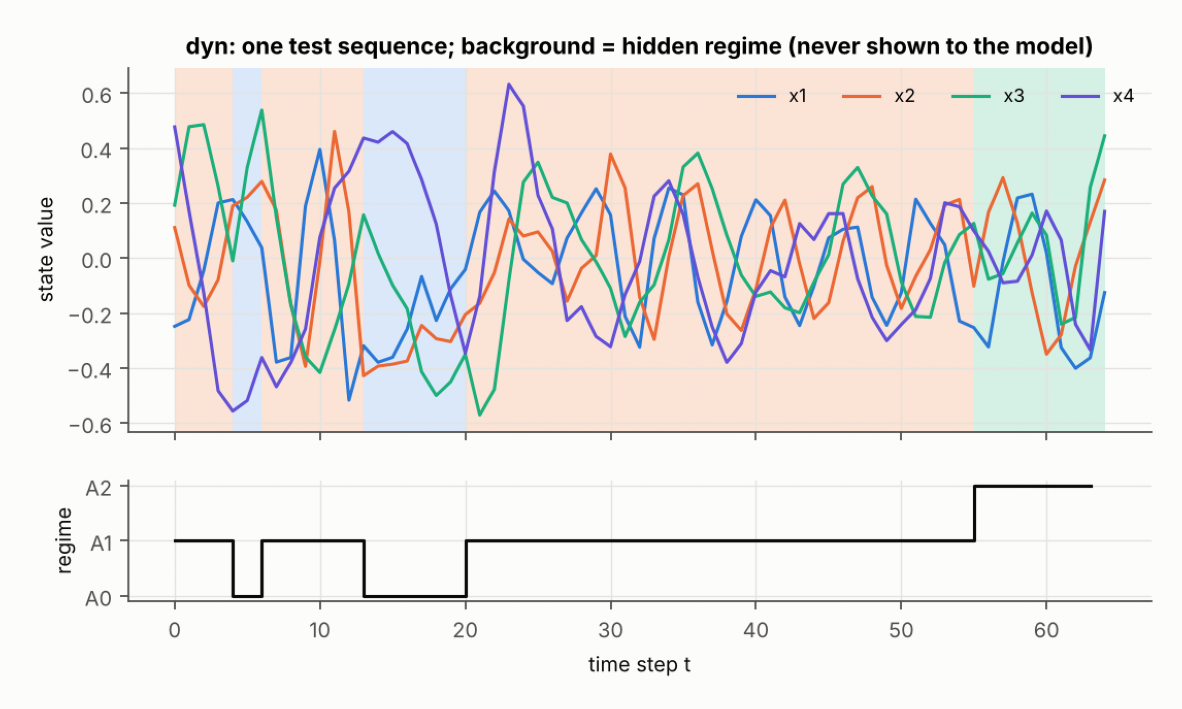

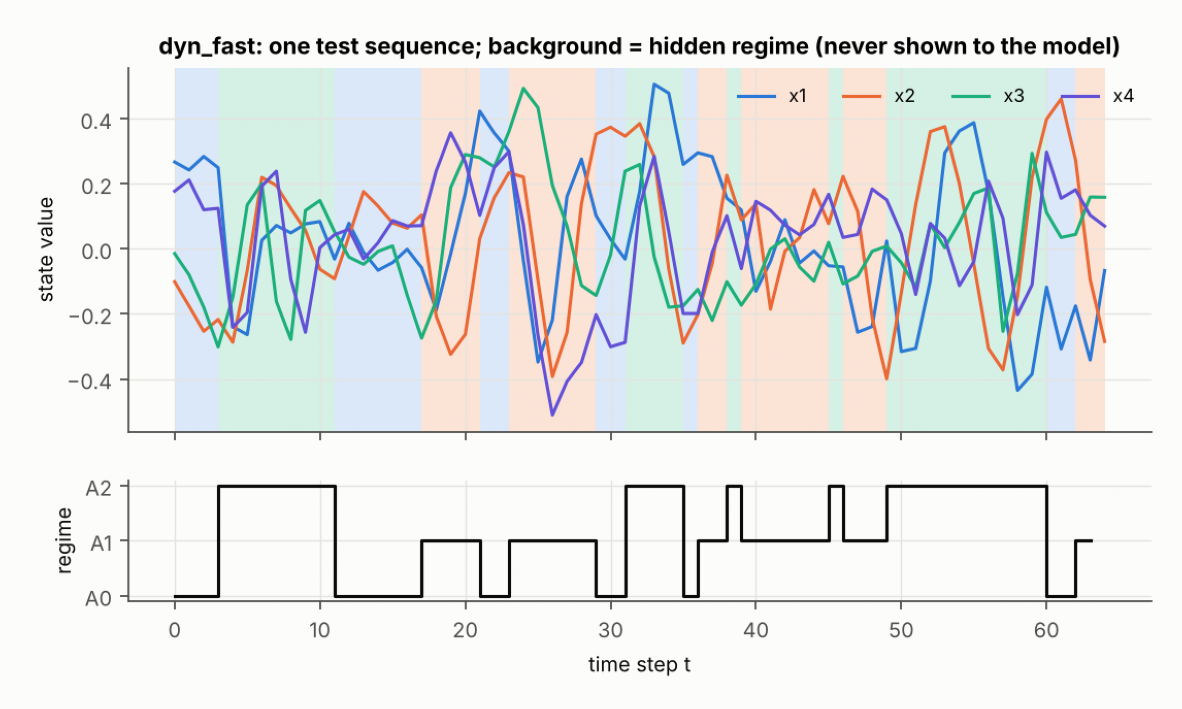

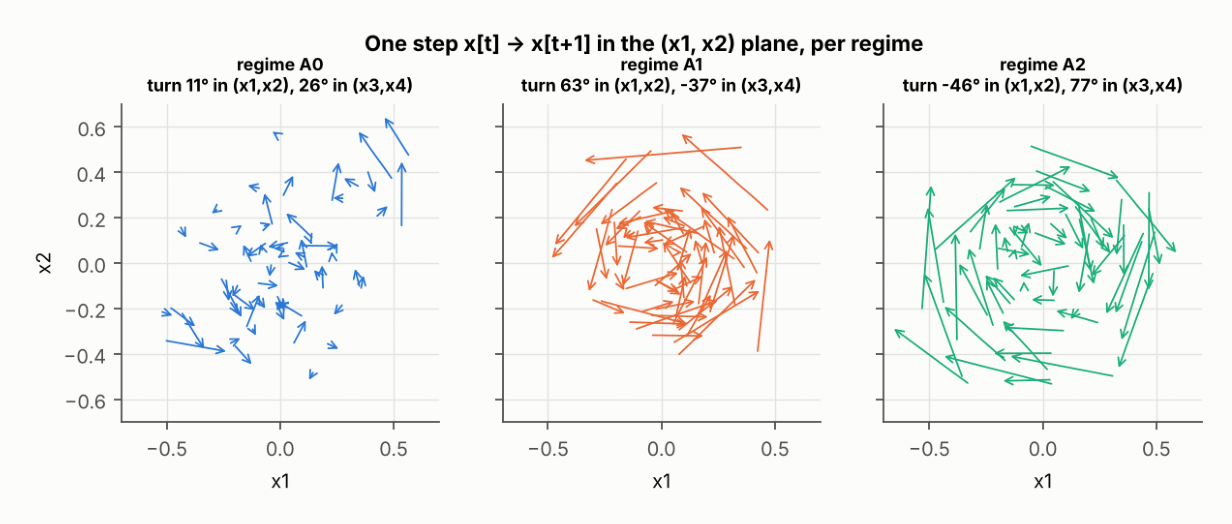

In [2]:
import numpy as np, matplotlib.pyplot as plt, matplotlib.image as mpimg
from analysis import dynamics as D
def show(p, size=(11, 5.5)):
    if p: plt.figure(figsize=size); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
print(json.dumps({k: v for k, v in json.loads((DATA_ROOT / "dyn" / "manifest.json").read_text()).items()
                  if k not in ("matrices", "splits")}, indent=1))
show(D.fig_example("dyn")); show(D.fig_example("dyn_fast")); show(D.fig_phase("dyn"), (11, 4))

## 2. Reference predictors (no learning)
`bayes_lastobs` is the floor: the best prediction once the past regime is known. Its remaining error is
almost all at age 0 (the step where the regime switches, which nobody can foresee).

In [3]:
from analysis.dyn_reference import references
ref = pd.concat([references(d) for d in D.DYN_DS]); display(ref.round(5))

,dataset,reference,mse,mse_ctx8,age_0,age_1,age_2,age_3,age_4-7,age_8+
0,dyn,oracle_true,0.00644,0.00644,0.00635,0.00647,0.00640,0.00643,0.00646,0.00644
1,dyn,oracle_lastobs,0.00997,0.01002,0.07755,0.00647,0.00640,0.00643,0.00646,0.00644
2,dyn,bayes_lastobs,0.00984,0.00989,0.07235,0.00660,0.00653,0.00657,0.00659,0.00658
3,dyn,infer_window1,0.01096,0.01056,0.07723,0.00704,0.00695,0.00705,0.00706,0.00702
4,dyn,infer_window2,0.01172,0.01136,0.07604,0.03321,0.00657,0.00655,0.00663,0.00660
5,dyn,infer_window4,0.01412,0.01388,0.07434,0.06468,0.03141,0.00857,0.00649,0.00647
6,dyn,infer_window8,0.01789,0.01808,0.07135,0.06843,0.05863,0.04372,0.01596,0.00644
7,dyn,persistence,0.04008,0.04008,0.03954,0.03962,0.03982,0.03977,0.03973,0.04028
8,dyn,zero,0.05512,0.05509,0.05414,0.05457,0.05450,0.05482,0.05500,0.05527
0,dyn_fast,oracle_true,0.00640,0.00641,0.00636,0.00637,0.00648,0.00642,0.00644,0.00639


## 3. Main comparison (default configs, 3 seeds)

,dataset,structure,mse,mse_sd,excess,excess_sd,excess_pct_of_floor,minus_dense,wins_vs_dense,params,n_x
0,dyn,dense,0.010080,0.000006,0.000192,0.000006,1.944278,0.000000,0,395776,3
1,dyn,dense_wide,0.010067,0.000009,0.000179,0.000009,1.806513,-0.000014,3,1185280,3
2,dyn,moa,0.010071,0.000008,0.000183,0.000008,1.849058,-0.000009,2,414208,3
6,dyn,moe,0.010068,0.000008,0.000180,0.000008,1.817110,-0.000013,3,1222144,3
8,dyn,moh,0.010050,0.000003,0.000162,0.000003,1.637442,-0.000030,3,529152,3
11,dyn,momha,0.010057,0.000001,0.000169,0.000001,1.707401,-0.000023,3,462592,3
13,dyn_fast,dense,0.019092,0.000008,0.000205,0.000008,1.083985,0.000000,0,395776,3
14,dyn_fast,dense_wide,0.019072,0.000002,0.000185,0.000002,0.978773,-0.000020,3,1185280,3
15,dyn_fast,moa,0.019070,0.000006,0.000183,0.000006,0.967314,-0.000022,3,414208,3
16,dyn_fast,moe,0.019076,0.000022,0.000188,0.000022,0.997388,-0.000016,2,1222144,3


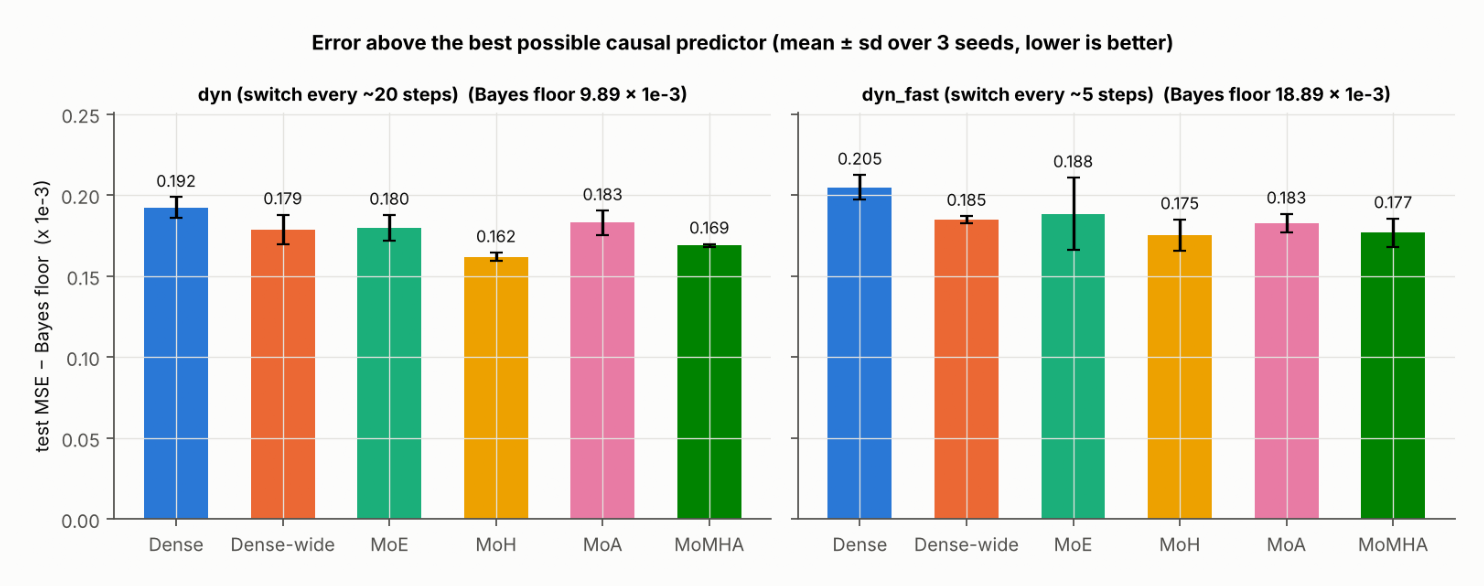

In [4]:
ref = D.references(); df, rt, hist = D.load()
df, main, age, roll, rtab = D.tables(df, rt, ref)
display(main[main.variant == "default"][["dataset", "structure", "mse", "mse_sd", "excess", "excess_sd",
        "excess_pct_of_floor", "minus_dense", "wins_vs_dense", "params", "n_x"]].round(6))
show(D.fig_main(main, ref), (12, 4.5))

## 4. Error around regime switches, rollout, learning curves

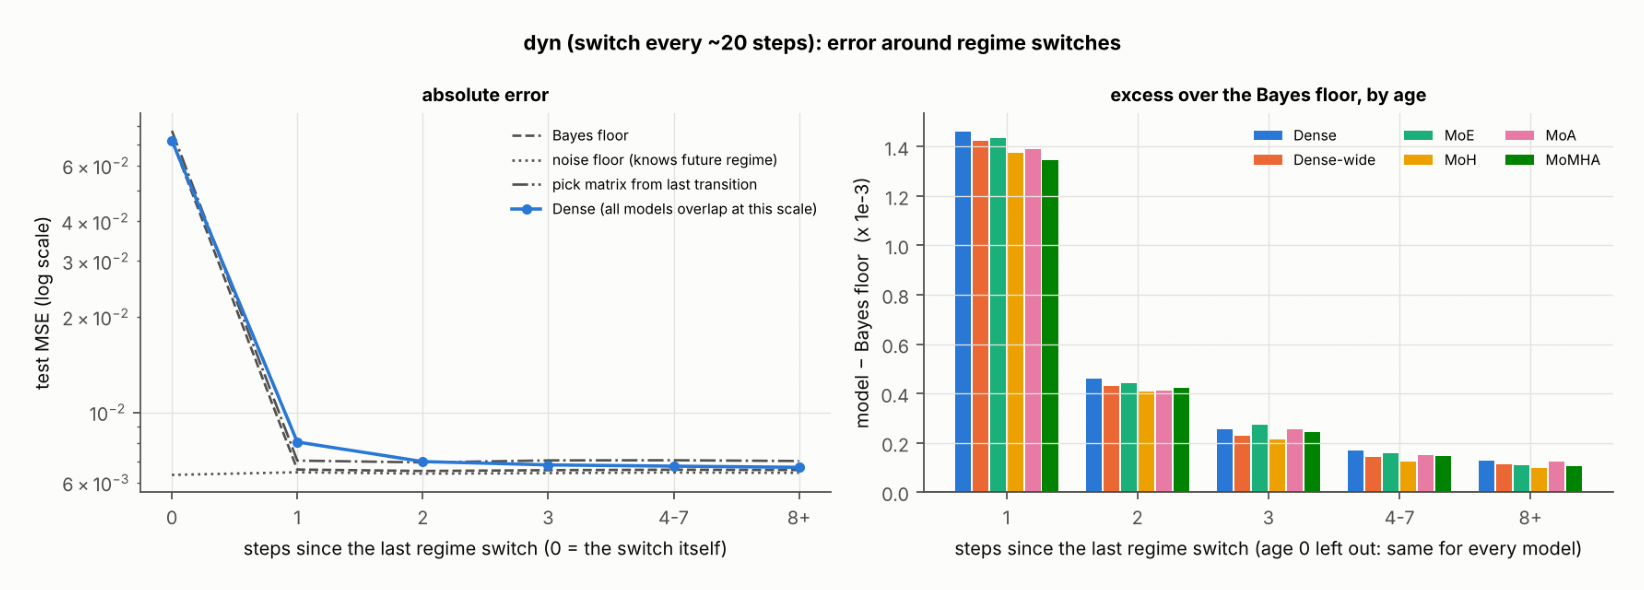

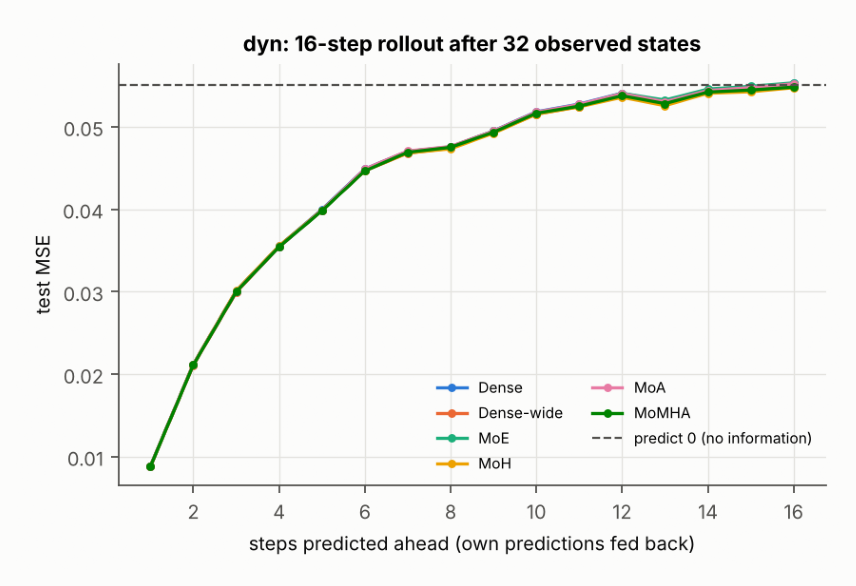

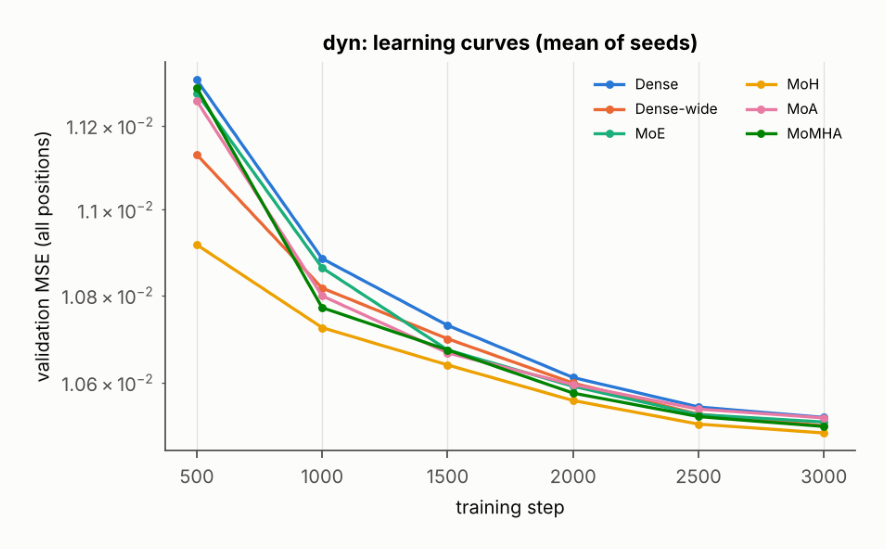

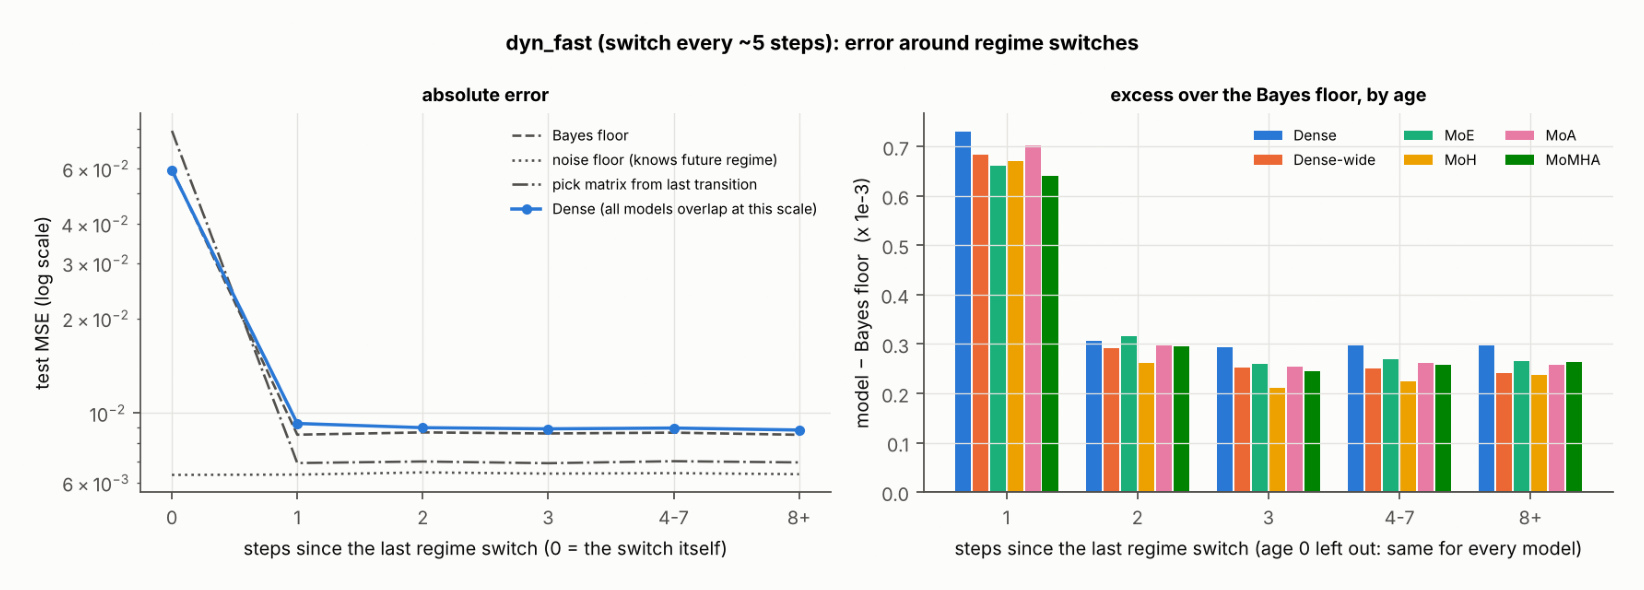

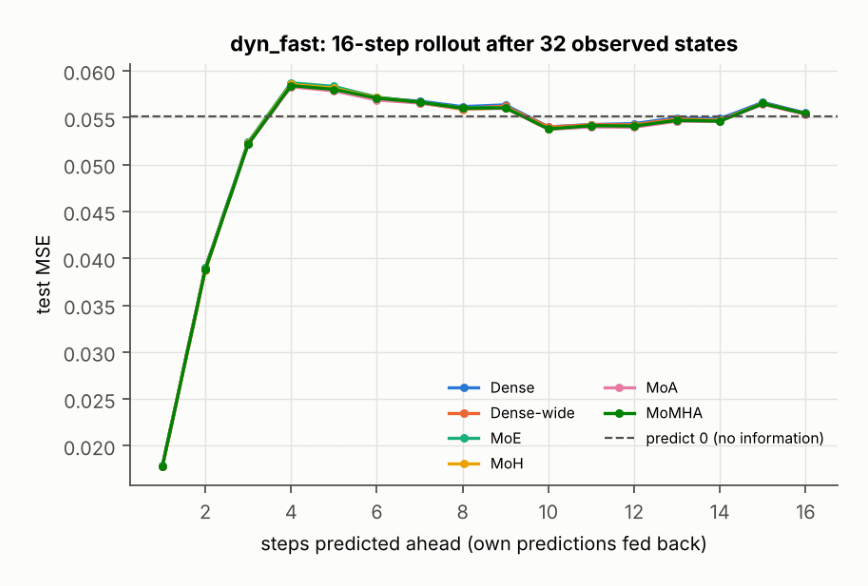

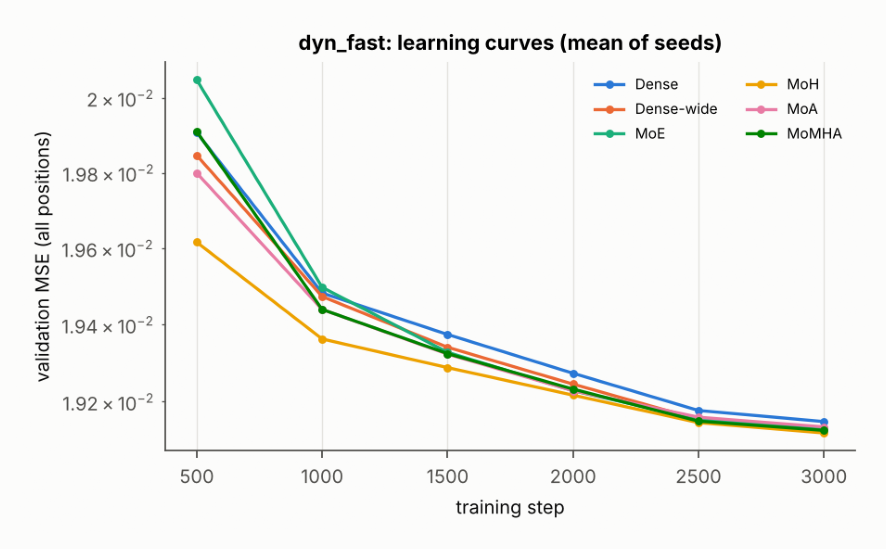

In [5]:
for ds in D.DYN_DS:
    show(D.fig_age(age, ref, ds), (13, 4.6)); show(D.fig_rollout(roll, ref, ds), (7.5, 4.5)); show(D.fig_curves(hist, ds), (7.5, 4.2))

## 5. Variants (dyn)

,structure,variant,excess,excess_sd,minus_dense,wins_vs_dense,n_x
0,dense,default,0.000192,0.000006,0.000000,0,3
1,dense_wide,default,0.000179,0.000009,-0.000014,3,3
2,moa,default,0.000183,0.000008,-0.000009,2,3
3,moa,k6,0.000184,0.000011,-0.000008,2,3
4,moa,k8,0.000195,0.000007,0.000003,1,3
5,moa,renorm_detached,0.000177,0.000005,-0.000015,3,3
6,moe,default,0.000180,0.000008,-0.000013,3,3
7,moe,top1,0.000219,0.000026,0.000027,0,3
8,moh,default,0.000162,0.000003,-0.000030,3,3
9,moh,k6,0.000160,0.000002,-0.000032,3,3


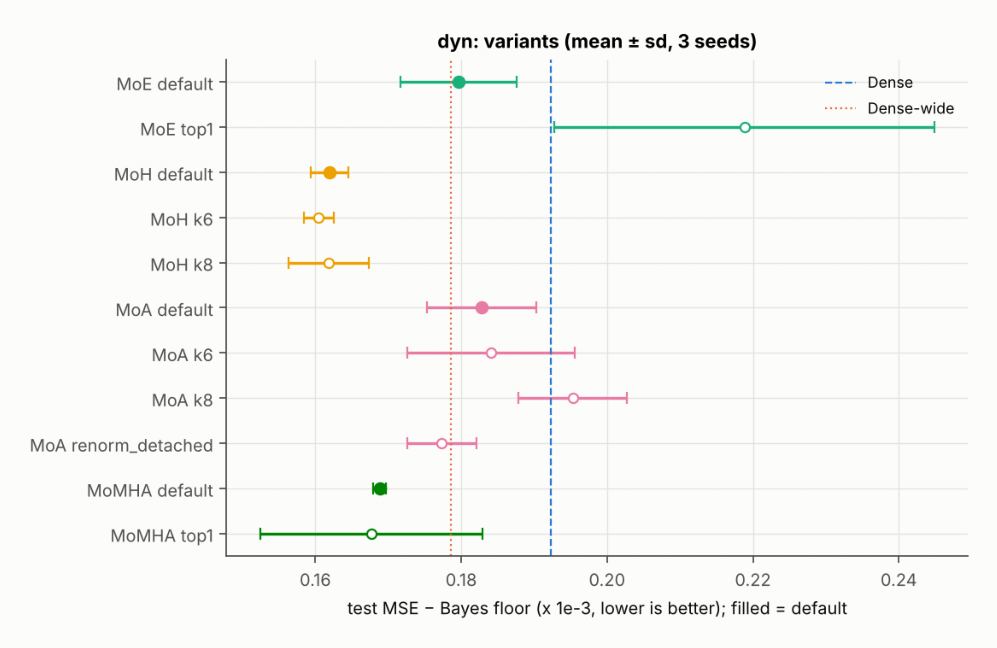

In [6]:
display(main[(main.dataset == "dyn")][["structure", "variant", "excess", "excess_sd", "minus_dense", "wins_vs_dense", "n_x"]].round(6))
show(D.fig_variants(main, "dyn"), (9, 5))

## 6. Does routing follow the hidden regime?
`regime_mi_obs` = mutual information between the unit a token is routed to and the regime of the last
observed transition, divided by log 3 (0 = routing ignores the regime, 1 = the unit identifies it).

,dataset,structure,variant,layer,kind,entropy,max_load,dead,regime_mi,regime_mi_obs,regime_mi_obs_sd
0,dyn,moa,default,0,attn,0.899,0.204,1.000,0.000,0.000,0.000
1,dyn,moa,default,1,attn,0.831,0.242,1.667,0.112,0.136,0.060
2,dyn,moa,k6,0,attn,0.965,0.160,0.333,0.000,0.000,0.000
3,dyn,moa,k6,1,attn,0.948,0.165,0.000,0.046,0.056,0.018
4,dyn,moa,k8,0,attn,1.000,0.125,0.000,0.000,0.000,0.000
5,dyn,moa,k8,1,attn,1.000,0.125,0.000,0.000,0.000,0.000
6,dyn,moa,renorm_detached,0,attn,0.926,0.194,0.333,0.000,0.000,0.000
7,dyn,moa,renorm_detached,1,attn,0.900,0.228,0.333,0.166,0.204,0.039
8,dyn,moe,default,0,ffn,0.595,0.436,4.000,0.041,0.049,0.027
9,dyn,moe,default,1,ffn,0.806,0.314,1.000,0.447,0.549,0.249


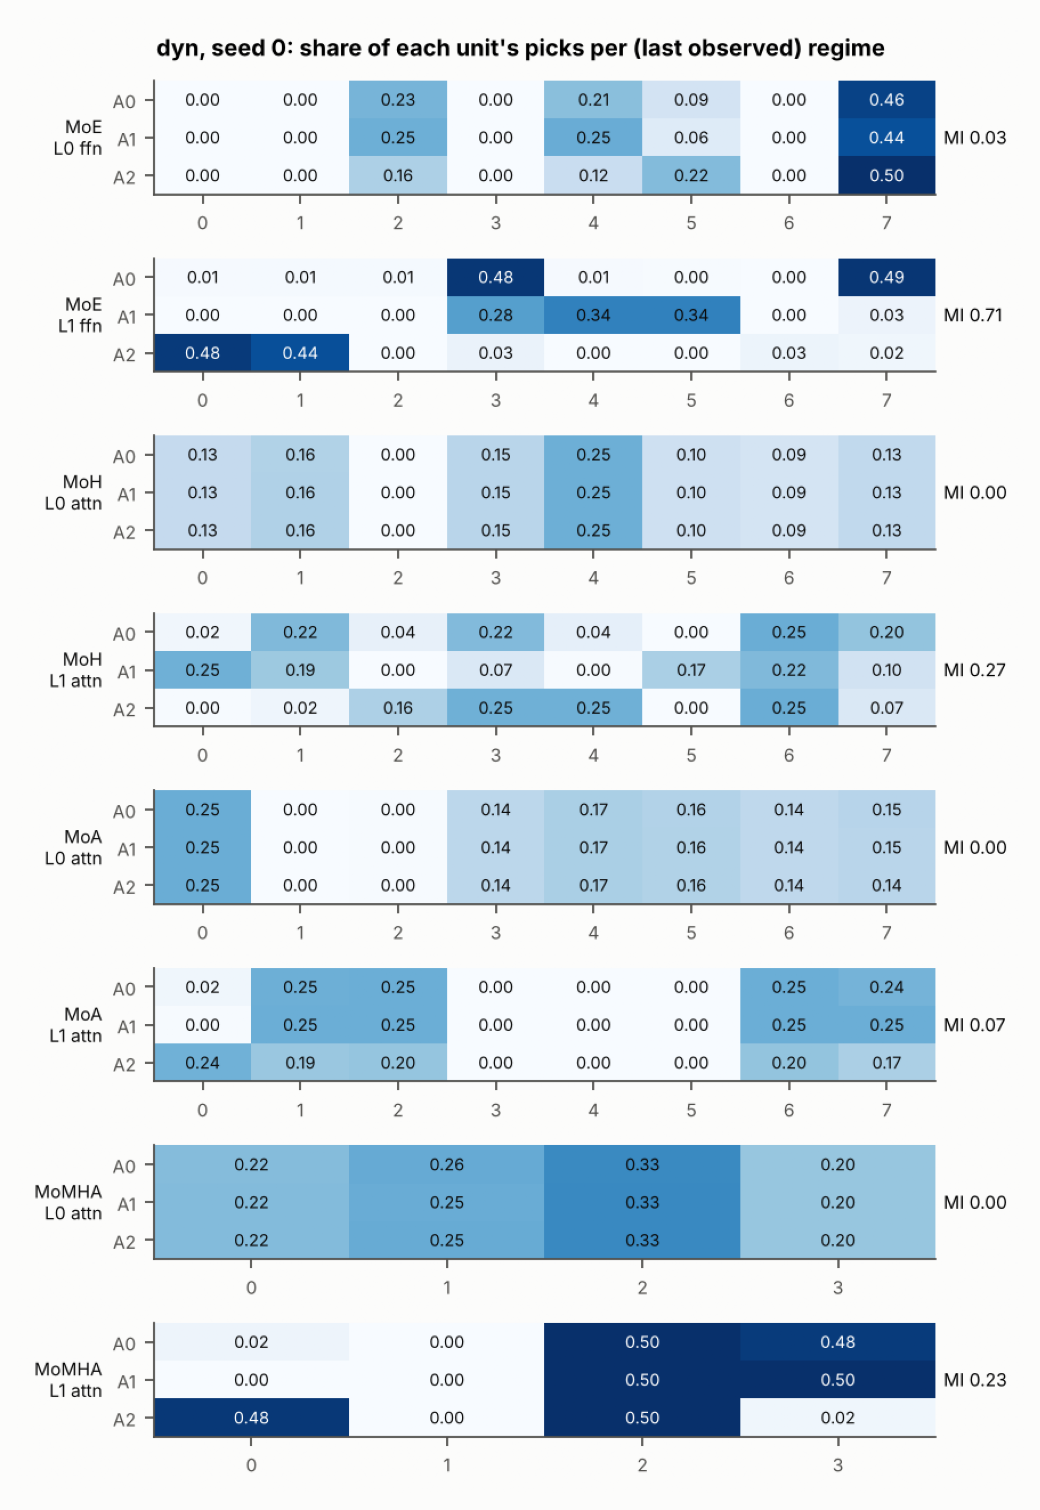

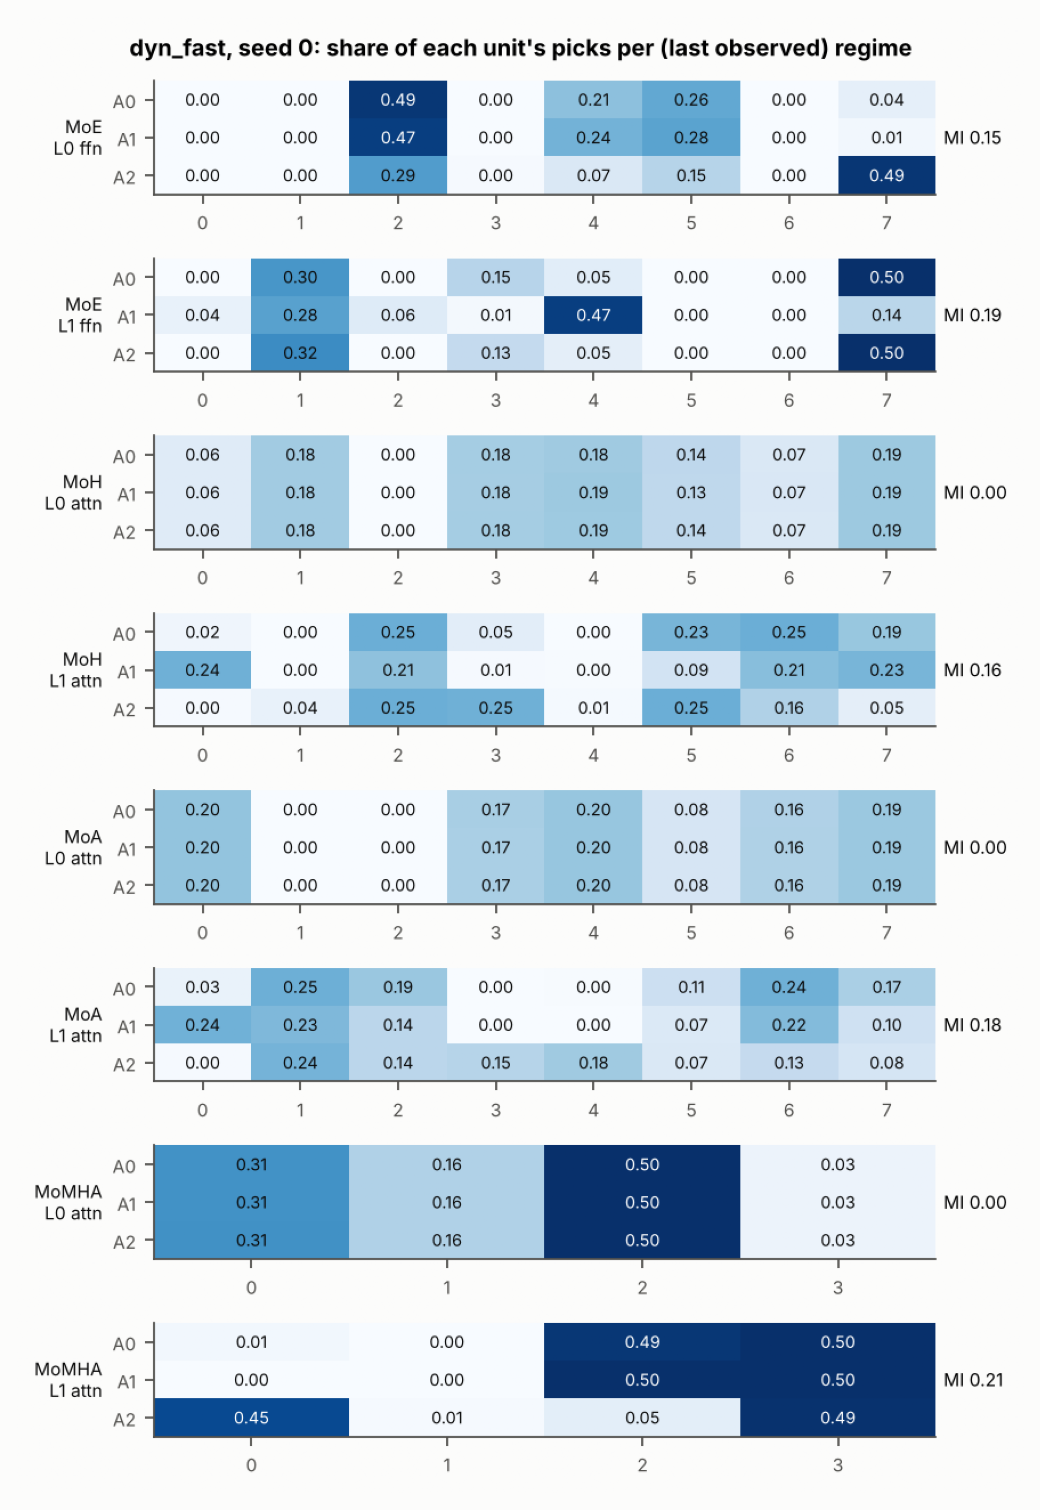

In [7]:
display(rtab.round(3))
for ds in D.DYN_DS:
    show(D.fig_regime_routing(rt, ds), (9, 12))